In [47]:
!pip install pytorch-geometric rdkit optuna pubchempy

In [190]:
import kagglehub
path = kagglehub.dataset_download("aryanamitbarsainyan/multi-labelled-smiles-odors-dataset")

In [ ]:
import os
from pathlib import Path
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW 
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch_geometric.utils import to_networkx # plot graph
import pandas as pd
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import optuna
from sklearn.model_selection import train_test_split # shoot gotta use scaffold for distribution
from sklearn.metrics import classification_report
from rdkit import Chem
from rdkit.Chem import Draw, rdFingerprintGenerator, AllChem, PandasTools, Descriptors
from rdkit.Chem.Draw import IPythonConsole 
import pubchempy as pcp
from tqdm.auto import tqdm

IPythonConsole.drawOptions.addAtomIndices = True

In [188]:
device = "cuda" if torch.cuda.is_available else "mps" if torch.backends.mps.is_available else "cpu"
device

'cuda'

In [191]:
path = Path(os.path.join(path, os.listdir(path)[0]))

In [225]:
df = pd.read_csv(path)
df.head(2)

,nonStereoSMILES,descriptors,alcoholic,aldehydic,alliaceous,almond,amber,animal,anisic,apple,...,tropical,vanilla,vegetable,vetiver,violet,warm,waxy,weedy,winey,woody
0,CC(O)CN,fishy,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,CCC(=O)C(=O)O,fatty;lactonic;sweet;caramellic;creamy,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [226]:
### Making sure meso compounds are the same by redoing the smiles using canonical
def clean_meso_stereochemistry(smiles): # ALSO ADDS HYDROGENS
    ''' 
    Takes in a MOL 
    '''
    # canonical=True consistent atom ordering
    # isomericSmiles=True get rid of that meso compound stuff want same embedding for meso
    mol = Chem.MolFromSmiles(smiles) 
    can_smiles = Chem.MolToSmiles(mol, canonical=True, isomericSmiles=True)
    return can_smiles


df["nonStereoSMILES"] = df["nonStereoSMILES"].map(lambda smiles: clean_meso_stereochemistry(smiles))

In [228]:
df.to_csv("no_stereochem.csv")
df = pd.read_csv("no_stereochem.csv", index_col = 0)
df.head(2)

,nonStereoSMILES,descriptors,alcoholic,aldehydic,alliaceous,almond,amber,animal,anisic,apple,...,tropical,vanilla,vegetable,vetiver,violet,warm,waxy,weedy,winey,woody
0,CC(O)CN,fishy,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,CCC(=O)C(=O)O,fatty;lactonic;sweet;caramellic;creamy,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Fetch names for smiles & merge into 1 dataframe

In [229]:
import urllib.parse
import requests
import time

names = []
num_retries = 5

for smile in tqdm(df["nonStereoSMILES"]):
    i = 0
    encoded_smiles = urllib.parse.quote(smile, safe="")

        ### https://pubchem.ncbi.nlm.nih.gov/rest/pug/<input specification>/<operation specification>/[<output specification>][?<operation_options>]
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/smiles/{encoded_smiles}/property/IUPACName/TXT"
    response = requests.get(url)
    
    if response.ok:
        names.append(response.text.strip())
        continue 

    # RETRIES
    while i < num_retries:        
        if i == 0:
            print(f"Retrying ATTEMPT {i} \n-------------------------------------------")
        else:
            print(f"Retrying ATTEMPT {i}")

        time.sleep(5)
        response = requests.get(url) 
        if response.ok:
            names.append(response.text.strip())
            break
        else:
            i += 1
    else:
        names.append(None)
        

  0%|          | 0/4983 [00:00<?, ?it/s]

Retrying ATTEMPT 0 
-------------------------------------------
Retrying ATTEMPT 1
Retrying ATTEMPT 2
Retrying ATTEMPT 3
Retrying ATTEMPT 4
Retrying ATTEMPT 0 
-------------------------------------------
Retrying ATTEMPT 1
Retrying ATTEMPT 2
Retrying ATTEMPT 3
Retrying ATTEMPT 4
Retrying ATTEMPT 0 
-------------------------------------------
Retrying ATTEMPT 1
Retrying ATTEMPT 2
Retrying ATTEMPT 3
Retrying ATTEMPT 4


In [231]:
comb_df = pd.concat([pd.DataFrame(names), df], axis = 1)
comb_df

,0,nonStereoSMILES,descriptors,alcoholic,aldehydic,alliaceous,almond,amber,animal,anisic,...,tropical,vanilla,vegetable,vetiver,violet,warm,waxy,weedy,winey,woody
0,1-aminopropan-2-ol,CC(O)CN,fishy,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2-oxobutanoic acid,CCC(=O)C(=O)O,fatty;lactonic;sweet;caramellic;creamy,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3-phenylpropanoic acid,O=C(O)CCc1ccccc1,rose;floral;fatty;sweet;musk;cinnamon;balsamic,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4-(hydroxymethyl)phenol,OCc1ccc(O)cc1,medicinal;phenolic;fruity;nutty;bitter;sweet;a...,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4-hydroxybenzaldehyde,O=Cc1ccc(O)cc1,phenolic;woody;nutty;vanilla;hay;metallic;swee...,0,0,0,1,0,0,0,...,0,1,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4978,"calcium [3,4-dihydroxy-5-(6-oxo-1H-purin-9-yl)...",O=c1[nH]cnc2c1ncn2C1OC(COP(=O)([O-])[O-])C(O)C...,odorless,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4979,"calcium [5-(2-amino-6-oxo-1H-purin-9-yl)-3,4-d...",Nc1nc2c(ncn2C2OC(COP(=O)([O-])[O-])C(O)C2O)c(=...,odorless,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4980,dipotassium;[5-(2-amino-6-oxo-1H-purin-9-yl)-3...,Nc1nc2c(ncn2C2OC(COP(=O)([O-])[O-])C(O)C2O)c(=...,odorless,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4981,"2-ethyl-4,6-dimethyl-4H-1,3,5-dithiazine",CCC1SC(C)=NC(C)S1,alliaceous,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [250]:
file_name = Path("cleaned_dataframe.csv")
comb_df.to_csv(file_name)

### Global descriptors and concat into UPDATED dataframe

In [329]:
df = pd.read_csv(file_name, index_col = 0)

In [330]:
df.head(2)

,Molecule Names,nonStereoSMILES,descriptors,alcoholic,aldehydic,alliaceous,almond,amber,animal,anisic,...,tropical,vanilla,vegetable,vetiver,violet,warm,waxy,weedy,winey,woody
0,1-aminopropan-2-ol,CC(O)CN,fishy,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2-oxobutanoic acid,CCC(=O)C(=O)O,fatty;lactonic;sweet;caramellic;creamy,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [215]:
# Global Properties
smiles = df.iloc[1000, 0]

# Add hydrogens
mol = Chem.AddHs(Chem.MolFromSmiles(smiles))
desc = Descriptors.CalcMolDescriptors(mol)
mol

[08:24:16] SMILES Parse Error: syntax error while parsing: <rdkit.Chem.rdchem.Mol
[08:24:16] SMILES Parse Error: check for mistakes around position 1:
[08:24:16] <rdkit.Chem.rdchem.Mol
[08:24:16] ^
[08:24:16] SMILES Parse Error: Failed parsing SMILES '<rdkit.Chem.rdchem.Mol' for input: '<rdkit.Chem.rdchem.Mol'


ArgumentError: Python argument types in
    rdkit.Chem.rdmolops.AddHs(NoneType)
did not match C++ signature:
    AddHs(RDKit::ROMol mol, bool explicitOnly=False, bool addCoords=False, boost::python::api::object onlyOnAtoms=None, bool addResidueInfo=False)
    AddHs(RDKit::ROMol mol, RDKit::MolOps::AddHsParameters params, boost::python::api::object onlyOnAtoms=None)

In [214]:
desc

{'MaxAbsEStateIndex': None,
 'MaxEStateIndex': None,
 'MinAbsEStateIndex': None,
 'MinEStateIndex': None,
 'qed': None,
 'SPS': None,
 'MolWt': None,
 'HeavyAtomMolWt': None,
 'ExactMolWt': None,
 'NumValenceElectrons': None,
 'NumRadicalElectrons': None,
 'MaxPartialCharge': None,
 'MinPartialCharge': None,
 'MaxAbsPartialCharge': None,
 'MinAbsPartialCharge': None,
 'FpDensityMorgan1': None,
 'FpDensityMorgan2': None,
 'FpDensityMorgan3': None,
 'BCUT2D_MWHI': nan,
 'BCUT2D_MWLOW': nan,
 'BCUT2D_CHGHI': nan,
 'BCUT2D_CHGLO': nan,
 'BCUT2D_LOGPHI': nan,
 'BCUT2D_LOGPLOW': nan,
 'BCUT2D_MRHI': nan,
 'BCUT2D_MRLOW': nan,
 'AvgIpc': None,
 'BalabanJ': None,
 'BertzCT': None,
 'Chi0': None,
 'Chi0n': None,
 'Chi0v': None,
 'Chi1': None,
 'Chi1n': None,
 'Chi1v': None,
 'Chi2n': None,
 'Chi2v': None,
 'Chi3n': None,
 'Chi3v': None,
 'Chi4n': None,
 'Chi4v': None,
 'HallKierAlpha': None,
 'Ipc': None,
 'Kappa1': None,
 'Kappa2': None,
 'Kappa3': None,
 'LabuteASA': None,
 'PEOE_VSA1': None,

In [ ]:
# from sklearn.preprocessing import StandardScaler, RobustScaler
from IPython.display import display

# from helper import normalize
# Trying out StandardScalar I think it work better than min max norm
# Listing all features, then grabbing columns and using standard/robust scalar to transform all of them 
# Global properties
props_i_want = [
    "ExactMolWt",
    "TPSA", 
    "RingCount", 
    "NumAromaticRings", 
    "MolLogP",
    "MolMR",
    "LabuteASA",
    "NumHDonors",
    "NumHAcceptors",
    "HeavyAtomCount",
    "NumRotatableBonds",
]

def get_prop_for_smile(smile):

    mol = Chem.MolFromSmiles(smile)
    h_mol = Chem.AddHs(mol)
    desc = Descriptors.CalcMolDescriptors(h_mol)

    morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    fp = np.array(morgan_gen.GetFingerprint(h_mol))
    row = {prop: desc[prop] for prop in props_i_want}
    row["MorganFingerprints"] = fp

    return pd.Series(row)


# morgan fingerprints 
# morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
# fp = morgan_gen.GetFingerprint(mol)
# np.array(fp)

In [478]:
fp_arr = []
def get_fp(smile):
    mol = Chem.MolFromSmiles(smile)
    h_mol = Chem.AddHs(mol)

    morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
    fp = np.array(morgan_gen.GetFingerprint(h_mol))
    fp_arr.append(fp)

[get_fp(smile) for smile in tqdm(df["nonStereoSMILES"])]

  0%|          | 0/4983 [00:00<?, ?it/s]

[None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,
 None,

In [500]:
finger_prints = np.array(fp_arr)
fp_df = pd.DataFrame(finger_prints, columns = [f'fp_{i}' for i in range(len(finger_prints[1]))])
fp_df.head()

,fp_0,fp_1,fp_2,fp_3,fp_4,fp_5,fp_6,fp_7,fp_8,fp_9,...,fp_2038,fp_2039,fp_2040,fp_2041,fp_2042,fp_2043,fp_2044,fp_2045,fp_2046,fp_2047
0,0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [313]:
rows =  [get_prop_for_smile(smile) for smile in tqdm(df["nonStereoSMILES"])]

  0%|          | 0/4983 [00:00<?, ?it/s]

In [338]:
prop_df = pd.DataFrame(rows, columns = [*props_i_want, "MorganFingerprints"])
prop_df.to_csv("properties_dataframe.csv", index = False)

In [341]:
df.head()

,Molecule Names,nonStereoSMILES,descriptors,alcoholic,aldehydic,alliaceous,almond,amber,animal,anisic,...,tropical,vanilla,vegetable,vetiver,violet,warm,waxy,weedy,winey,woody
0,1-aminopropan-2-ol,CC(O)CN,fishy,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2-oxobutanoic acid,CCC(=O)C(=O)O,fatty;lactonic;sweet;caramellic;creamy,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3-phenylpropanoic acid,O=C(O)CCc1ccccc1,rose;floral;fatty;sweet;musk;cinnamon;balsamic,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4-(hydroxymethyl)phenol,OCc1ccc(O)cc1,medicinal;phenolic;fruity;nutty;bitter;sweet;a...,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,4-hydroxybenzaldehyde,O=Cc1ccc(O)cc1,phenolic;woody;nutty;vanilla;hay;metallic;swee...,0,0,0,1,0,0,0,...,0,1,0,0,0,0,0,0,0,1


In [339]:
props_df = pd.read_csv("properties_dataframe.csv")
props_df.head()

,ExactMolWt,TPSA,RingCount,NumAromaticRings,MolLogP,MolMR,LabuteASA,NumHDonors,NumHAcceptors,HeavyAtomCount,NumRotatableBonds,MorganFingerprints
0,75.068414,46.25,0,0,-0.6741,20.7352,44.450778,2,2,5,3,[0 1 0 ... 0 0 0]
1,102.031694,54.37,0,0,0.0501,22.9338,49.467849,1,3,7,2,[0 0 0 ... 0 0 0]
2,150.068080,37.30,1,1,1.7038,42.3988,79.618361,1,2,11,3,[0 0 0 ... 0 0 0]
3,124.052429,40.46,1,1,0.8845,34.0296,64.797917,2,2,9,3,[0 0 0 ... 0 0 0]
4,122.036779,37.30,1,1,1.2047,33.4943,61.268594,1,2,9,2,[0 0 0 ... 0 0 0]


In [421]:
finger_prints = props_df["MorganFingerprints"]
finger_prints.head(2)

0    [0 1 0 ... 0 0 0]
1    [0 0 0 ... 0 0 0]
Name: MorganFingerprints, dtype: object

In [422]:
for col in props_df.drop(["MorganFingerprints"], axis = 1).columns:
    props_df[col] = pd.to_numeric(props_df[col])

props_df.dtypes

ExactMolWt            float64
TPSA                  float64
RingCount               int64
NumAromaticRings        int64
MolLogP               float64
MolMR                 float64
LabuteASA             float64
NumHDonors              int64
NumHAcceptors           int64
HeavyAtomCount          int64
NumRotatableBonds       int64
MorganFingerprints     object
dtype: object

In [424]:
props_numpy = props_df.drop(["MorganFingerprints"], axis = 1).to_numpy()
props_numpy.shape

(4983, 11)

In [502]:
props_df.columns[:-1]

Index(['ExactMolWt', 'TPSA', 'RingCount', 'NumAromaticRings', 'MolLogP',
       'MolMR', 'LabuteASA', 'NumHDonors', 'NumHAcceptors', 'HeavyAtomCount',
       'NumRotatableBonds'],
      dtype='object')

In [516]:
df.head(2)

,Molecule Names,nonStereoSMILES,descriptors,alcoholic,aldehydic,alliaceous,almond,amber,animal,anisic,...,tropical,vanilla,vegetable,vetiver,violet,warm,waxy,weedy,winey,woody
0,1-aminopropan-2-ol,CC(O)CN,fishy,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2-oxobutanoic acid,CCC(=O)C(=O)O,fatty;lactonic;sweet;caramellic;creamy,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [520]:
df.iloc[:, 0]

0                                      1-aminopropan-2-ol
1                                      2-oxobutanoic acid
2                                  3-phenylpropanoic acid
3                                 4-(hydroxymethyl)phenol
4                                   4-hydroxybenzaldehyde
                              ...                        
4978    calcium [3,4-dihydroxy-5-(6-oxo-1H-purin-9-yl)...
4979    calcium [5-(2-amino-6-oxo-1H-purin-9-yl)-3,4-d...
4980    dipotassium;[5-(2-amino-6-oxo-1H-purin-9-yl)-3...
4981             2-ethyl-4,6-dimethyl-4H-1,3,5-dithiazine
4982    2-methyl-3-(5-methyl-2-propan-2-ylcyclohexyl)o...
Name: Molecule Names, Length: 4983, dtype: object

In [ ]:
from sklearn.preprocessing import RobustScaler, StandardScaler 

# Normalize all features except for morgan fingerprints 
# Use standardscaler
scaler = StandardScaler()
X = scaler.fit_transform(props_numpy)
X_full = pd.concat([df.iloc[:, 0], df.iloc[:, 1], pd.DataFrame(X, columns = props_df.columns[:-1]), fp_df], axis = 1)
X_full

,Molecule Names,nonStereoSMILES,ExactMolWt,TPSA,RingCount,NumAromaticRings,MolLogP,MolMR,LabuteASA,NumHDonors,...,fp_2038,fp_2039,fp_2040,fp_2041,fp_2042,fp_2043,fp_2044,fp_2045,fp_2046,fp_2047
0,1-aminopropan-2-ol,CC(O)CN,-1.488030,0.554475,-0.193834,-0.612255,-1.536343,-1.568402,-1.453295,1.642413,...,0,0,0,0,0,0,0,0,0,0
1,2-oxobutanoic acid,CCC(=O)C(=O)O,-1.106809,0.820781,-0.193834,-0.612255,-1.178528,-1.457416,-1.328150,0.617473,...,0,0,0,0,0,0,0,0,0,0
2,3-phenylpropanoic acid,O=C(O)CCc1ccccc1,-0.427645,0.260949,0.034182,1.140109,-0.361462,-0.474818,-0.576081,0.617473,...,0,0,0,0,0,0,0,0,0,0
3,4-(hydroxymethyl)phenol,OCc1ccc(O)cc1,-0.795468,0.364585,0.034182,1.140109,-0.766265,-0.897297,-0.945760,1.642413,...,0,0,0,0,0,0,0,0,0,0
4,4-hydroxybenzaldehyde,O=Cc1ccc(O)cc1,-0.823966,0.260949,0.034182,1.140109,-0.608059,-0.924320,-1.033795,0.617473,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4978,"calcium [3,4-dihydroxy-5-(6-oxo-1H-purin-9-yl)...",O=c1[nH]cnc2c1ncn2C1OC(COP(=O)([O-])[O-])C(O)C...,2.908001,5.127255,0.490214,2.892473,-3.079167,1.089362,1.901057,2.667352,...,0,0,0,0,0,0,0,0,0,0
4979,"calcium [5-(2-amino-6-oxo-1H-purin-9-yl)-3,4-d...",Nc1nc2c(ncn2C2OC(COP(=O)([O-])[O-])C(O)C2O)c(=...,3.120233,5.980613,0.490214,2.892473,-3.285595,1.312100,2.072196,3.692292,...,0,0,0,0,0,0,0,0,0,0
4980,dipotassium;[5-(2-amino-6-oxo-1H-purin-9-yl)-3...,Nc1nc2c(ncn2C2OC(COP(=O)([O-])[O-])C(O)C2O)c(=...,3.657000,5.980613,0.490214,2.892473,-6.057995,1.021637,3.611963,3.692292,...,0,0,0,0,0,0,0,0,0,0
4981,"2-ethyl-4,6-dimethyl-4H-1,3,5-dithiazine",CCC1SC(C)=NC(C)S1,-0.074452,-0.556989,0.034182,-0.612255,0.262614,0.001372,-0.333855,-0.407466,...,0,0,0,0,0,0,0,0,0,0


### Edge/Bond features

In [ ]:
df.columns.get_loc("nonStereoSMILES")

1

In [ ]:
mol = Chem.MolFromSmiles(df.iloc[4920,1])

def get_bond_amounts(mol):
    num_single, num_double, num_triple, num_aromatic = 0,0,0,0
    for bond in mol.GetBonds():
        bond_type = bond.GetBondType()
        # print(bond_type)
        if str(bond_type) == "SINGLE":
            num_single += 1
        elif str(bond_type) == "AROMATIC":
            num_aromatic += 1
        elif str(bond_type) == "DOUBLE":
            num_double += 1
        else: # Triple bond
            num_triple += 1 

    print(f"SINGLE: {num_single} \n DOUBLE: {num_double} \n TRIPLE: {num_triple} \n AROMATIC: {num_aromatic}")

    return num_single, num_double, num_triple, num_aromatic

get_bond_amounts(mol)

SINGLE: 8 
 DOUBLE: 1 
 TRIPLE: 0 
 AROMATIC: 6


(8, 1, 0, 6)

0 1
1 0
1 2
2 1


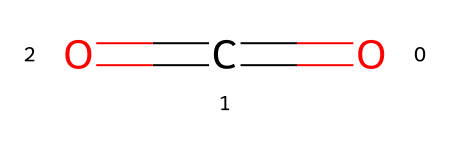

In [ ]:
''' 
Create (2, num_edge) array, ex:
[[1,2,3],
[2,3,4]]

1 -> 2
2 -> 3
3 -> 4

So arr would be 1 -> 2 -> 3 -> 4
But our molecule is bidirectional (bond connects from A->B AND B->A)
THIS MEANS FOR EDGE PROPERTIES I GOTTA PRINT IT TWICE BASCIALLY PER BOND 
'''

mol = Chem.MolFromSmiles("O=C=O")
for bond in mol.GetBonds():
    print(bond.GetBeginAtomIdx(), bond.GetEndAtomIdx())
    print(bond.GetEndAtomIdx(), bond.GetBeginAtomIdx())

mol

Bond length: 1.784 | Bond angle: 109.47120948225599


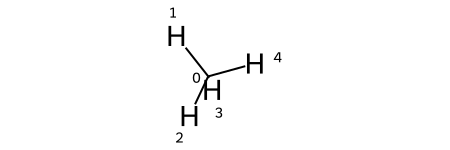

In [ ]:
from rdkit import Chem
from rdkit.Chem import AllChem, rdMolTransforms

# Tinkering with force field optimization
mol = Chem.MolFromSmiles("C")
mol = Chem.AddHs(mol)
AllChem.EmbedMolecule(mol, randomSeed=42)
AllChem.MMFFOptimizeMolecule(mol)  

# optimized conformer and measure distance anstrom between atom indices
conf = mol.GetConformer()
length = rdMolTransforms.GetBondLength(conf, 2, 1)
angle = rdMolTransforms.GetAngleDeg(conf, 1,0,2)
print(f"Bond length: {length:.3f} | Bond angle: {angle}") # makes sense it's ~109.5 cuz tetrahedral
mol

In [ ]:
# bond_props_i_want = [

# ]

for bond in mol.GetBonds():
    # bond.GetIsConjugated
    # bond.GetIsAromatic 
    # bond.IsInRing 
    # bond.GetStereo
    # bond.IsInRingSize 
    props = bond.GetStereo()
    
    # prop = bond.
    break

props.STEREOCIS

rdkit.Chem.rdchem.BondStereo.STEREOCIS

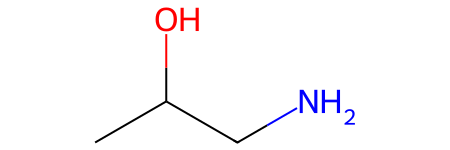

In [ ]:
smiles_list = df.iloc[:, 0]
mols_list = smiles_list.map(lambda smile: Chem.MolFromSmiles(smile))
mols_list.iloc[0]

### Node/atom features. Creating functions for normalizing the features
- Finding smallest & biggest atom, normalizing by that atomic weight

In [ ]:
# Create set of atoms. normalize features based on the type of atoms in the dataset 
unique_atoms_atomic_number = []
unique_atoms_name = []
for mol in tqdm(mols_list):
    for atom in mol.GetAtoms():
        atomic_num = atom.GetAtomicNum()
        if atomic_num not in unique_atoms_atomic_number:
            unique_atoms_atomic_number.append(atomic_num)
            unique_atoms_name.append(atom.GetSymbol())

  0%|          | 0/4983 [00:00<?, ?it/s]

In [ ]:
print(len(unique_atoms_name))

25


In [ ]:
min_anum, max_anum = min(unique_atoms_atomic_number), max(unique_atoms_atomic_number) 
### Normalize everything using min max properties from these 2 elements
periodic_table = Chem.GetPeriodicTable()
periodic_table.GetElementSymbol(min_anum), periodic_table.GetElementSymbol(max_anum)

('He', 'Bi')

In [ ]:
unique_atoms_name

['C',
 'O',
 'N',
 'S',
 'Cl',
 'K',
 'Ca',
 'Na',
 'P',
 'Br',
 'Si',
 'Mg',
 'Fe',
 'Zn',
 'V',
 'Cu',
 'He',
 'I',
 'Co',
 'Al',
 'Ti',
 'Cr',
 'B',
 'Bi',
 'F']

In [ ]:
Y = df.iloc[:, 2:].to_numpy() # labels 

In [ ]:
classes = df.iloc[:, 2:].columns # names of smells
num_classes = len(classes)
num_classes

138

In [ ]:
first = df.iloc[0,2:]
first[first == 1]

fishy    1
Name: 0, dtype: object

In [ ]:
first_numpy_arr = df.iloc[:, 2:].to_numpy()[0]
idx = np.where(first_numpy_arr == 1)
classes[idx] # nice matches up with prev 

Index(['fishy'], dtype='object')

<Axes: >

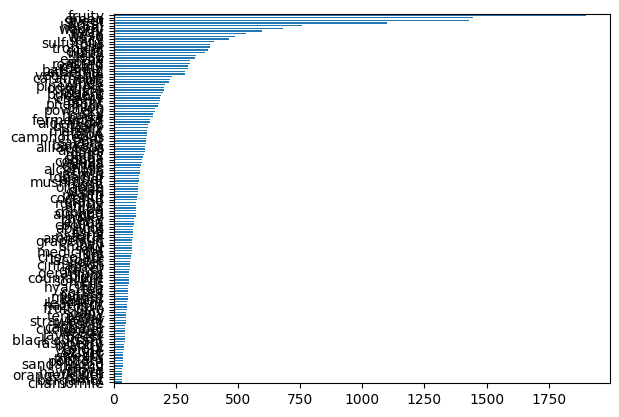

In [ ]:
# class distribution
df.iloc[:, 2:].sum().sort_values().plot(kind = "barh")

### Merge metadata from pubchem database. Potentially test feature importance

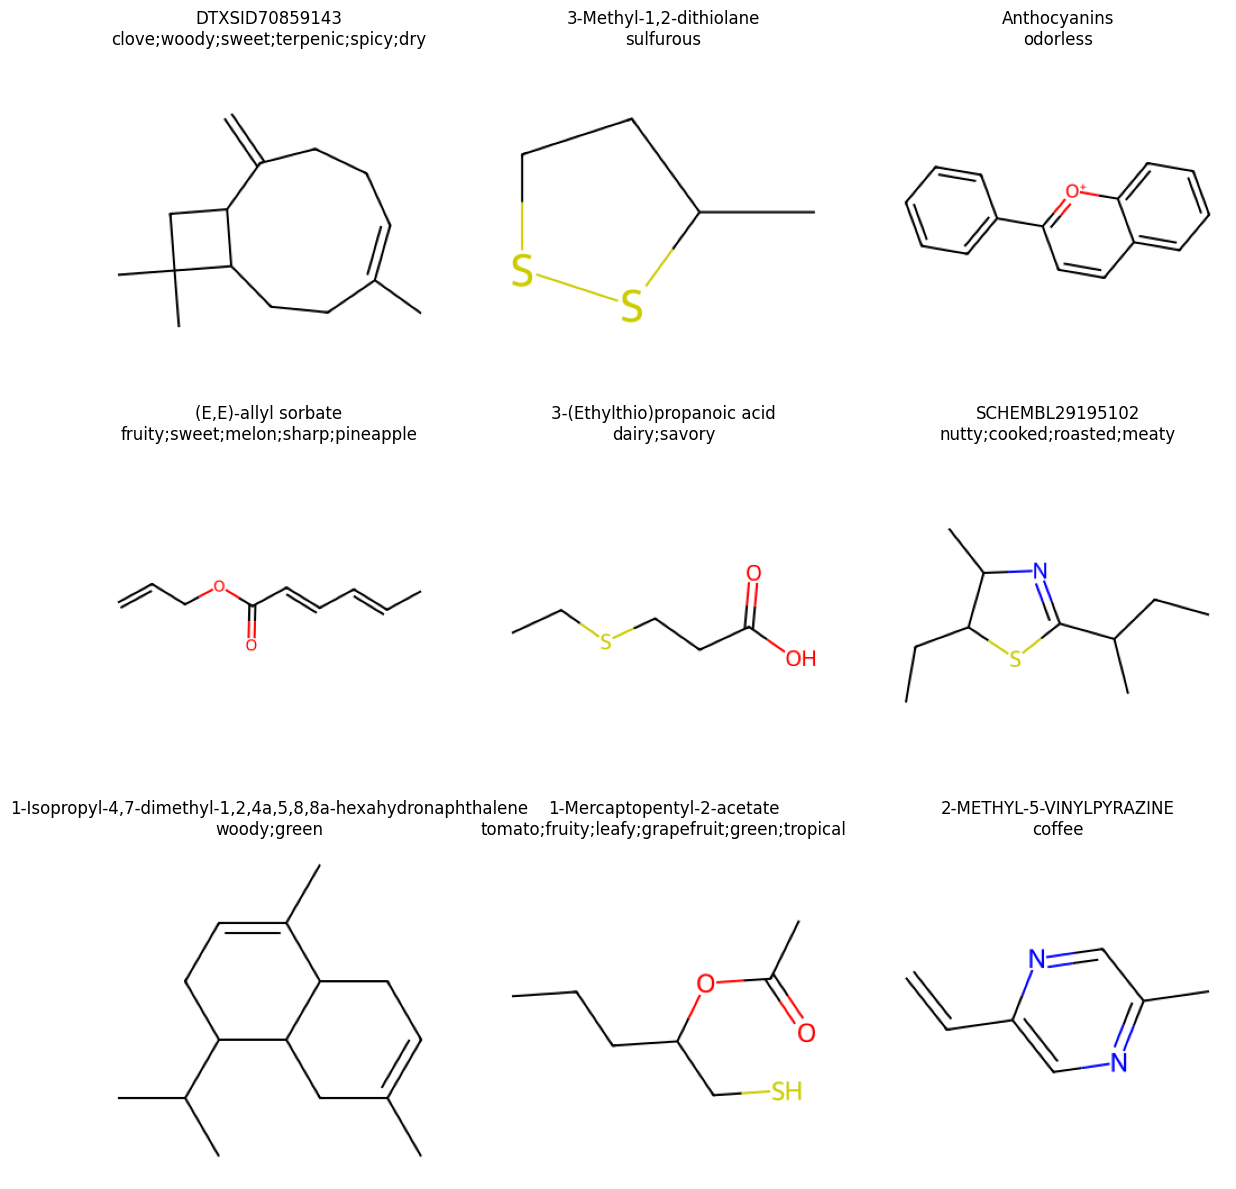

In [ ]:
def visualize_molecules(df):
  rand_numbers = np.random.randint(0, len(df), 9)
  fig, axes = plt.subplots(3, 3, figsize=(12, 12))
  axes = axes.flatten()
  for i in range(9):
    smiles = df[int(rand_numbers[i]),0]
    mol = Chem.MolFromSmiles(smiles)
    img = Draw.MolToImage(mol)
    axes[i].imshow(img)
    name = pcp.get

    compounds = pcp.get_compounds(smiles, namespace='smiles')

    if compounds:
        compound = compounds[0]
        name = compound.synonyms
        if name:
            name = name[0]
        else:
            name = 'Unknown'
    else:
        name = 'Unknown'

    smell_cats = df[int(rand_numbers[i]), 1]

    axes[i].set_title(name + "\n" + smell_cats)
    axes[i].axis('off')

  plt.tight_layout()
  plt.show()

  return None

visualize_molecules(df)


## Apply PCA to analyze the labels
- Try to find top k most common features in the dataset

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

pca = PCA(n_components = 2)


In [ ]:
scaler = StandardScaler()

X = df[:,0]
Y = df[:,2:]
Y_scaled = scaler.fit_transform(Y)
labels = Y.columns

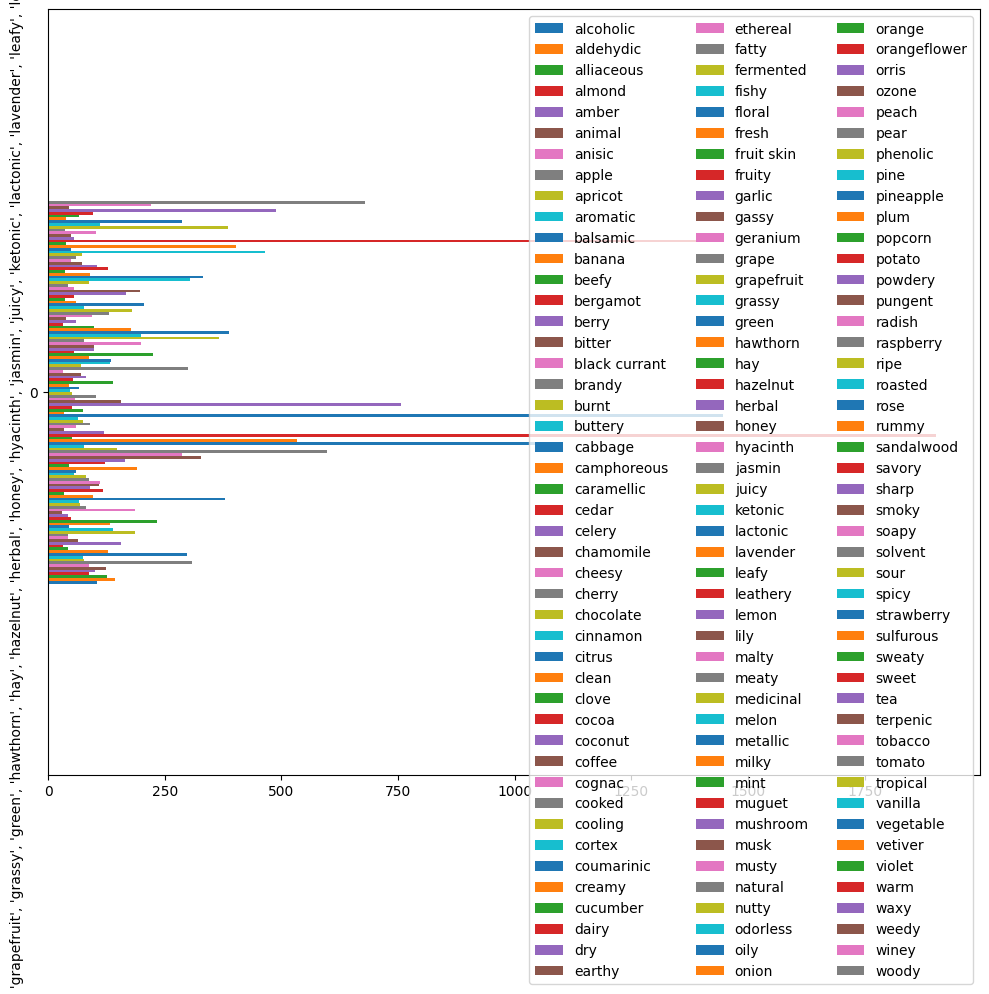

In [ ]:
# Class features
total_categories_sum = Y.sum().to_pandas()

total_categories_sum.plot.barh(figsize = (10,10))
plt.ylabel(labels)
plt.legend(ncols=3)
plt.tight_layout()
plt.show()

### Create the dataset

In [ ]:
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import StratifiedGroupKFold # Using k_fold validation
from torch_geometric.data import Data, Dataset, DataLoader

In [ ]:
class MoleculeDataset(Dataset):
    def __init__(self, root, filename, test=True, transform=None, pre_transform=None):
        """
        root = Where the dataset should be stored. This folder is split
        into raw_dir (downloaded dataset) and processed_dir (processed data). 
        """
        self.test = test
        self.filename = filename
        super(MoleculeDataset, self).__init__(root, transform, pre_transform)
        
    @property
    def raw_file_names(self):
        """ If this file exists in raw_dir, the download is not triggered.
            (The download func. is not implemented here)  
        """
        return self.filename

    @property
    def processed_file_names(self):
        """ If these files are found in raw_dir, processing is skipped"""
        self.data = pd.read_csv(self.raw_paths[0]).reset_index()

        if self.test:
            return [f'data_test_{i}.pt' for i in list(self.data.index)]
        else:
            return [f'data_{i}.pt' for i in list(self.data.index)]

    def download(self):
        pass

    def process(self):
        self.data = pd.read_csv(self.raw_paths[0])
        for index, mol in tqdm(self.data.iterrows(), total=self.data.shape[0]):
            mol_obj = Chem.MolFromSmiles(mol["smiles"])
            # Get node features
            node_feats = self._get_node_features(mol_obj)
            # Get edge features
            edge_feats = self._get_edge_features(mol_obj)
            # Get adjacency info
            edge_index = self._get_adjacency_info(mol_obj)
            # Get labels info
            label = self._get_labels(mol["HIV_active"])

            # Create data object
            data = Data(x=node_feats, 
                        edge_index=edge_index,
                        edge_attr=edge_feats,
                        y=label,
                        smiles=mol["smiles"]
                        ) 
            if self.test:
                torch.save(data, 
                    os.path.join(self.processed_dir, 
                                 f'data_test_{index}.pt'))
            else:
                torch.save(data, 
                    os.path.join(self.processed_dir, 
                                 f'data_{index}.pt'))

    def _get_node_features(self, mol):
        """ 
        This will return a matrix / 2d array of the shape
        [Number of Nodes, Node Feature size]
        """
        all_node_feats = []

        for atom in mol.GetAtoms():
            node_feats = []
            # Feature 1: Atomic number        
            node_feats.append(atom.GetAtomicNum())
            # Feature 2: Atom degree
            node_feats.append(atom.GetDegree())
            # Feature 3: Formal charge
            node_feats.append(atom.GetFormalCharge())
            # Feature 4: Hybridization
            node_feats.append(atom.GetHybridization())
            # Feature 5: Aromaticity
            node_feats.append(atom.GetIsAromatic())
            # Feature 6: Total Num Hs
            node_feats.append(atom.GetTotalNumHs())
            # Feature 7: Radical Electrons
            node_feats.append(atom.GetNumRadicalElectrons())
            # Feature 8: In Ring
            node_feats.append(atom.IsInRing())
            # Feature 9: Chirality
            node_feats.append(atom.GetChiralTag())

            # Append node features to matrix
            all_node_feats.append(node_feats)

        all_node_feats = np.asarray(all_node_feats)
        return torch.tensor(all_node_feats, dtype=torch.float)

    def _get_edge_features(self, mol):
        """ 
        This will return a matrix / 2d array of the shape
        [Number of edges, Edge Feature size]
        """
        all_edge_feats = []

        for bond in mol.GetBonds():
            edge_feats = []
            # Feature 1: Bond type (as double)
            edge_feats.append(bond.GetBondTypeAsDouble())
            # Feature 2: Rings
            edge_feats.append(bond.IsInRing())
            # Append node features to matrix (twice, per direction)
            all_edge_feats += [edge_feats, edge_feats]

        all_edge_feats = np.asarray(all_edge_feats)
        return torch.tensor(all_edge_feats, dtype=torch.float)

    def _get_adjacency_info(self, mol):
        """
        We could also use rdmolops.GetAdjacencyMatrix(mol)
        but we want to be sure that the order of the indices
        matches the order of the edge features
        """
        edge_indices = []
        for bond in mol.GetBonds():
            i = bond.GetBeginAtomIdx()
            j = bond.GetEndAtomIdx()
            # bidirectional graph
            edge_indices += [[i, j], [j, i]]

        edge_indices = torch.tensor(edge_indices)
        edge_indices = edge_indices.t().to(torch.long).view(2, -1)
        return edge_indices

    def _get_labels(self, label):
        label = np.asarray([label])
        return torch.tensor(label, dtype=torch.int64)

    def len(self):
        return self.data.shape[0]

    def get(self, idx):
        """ - Equivalent to __getitem__ in pytorch
            - Is not needed for PyG's InMemoryDataset
        """
        if self.test:
            data = torch.load(os.path.join(self.processed_dir, 
                                 f'data_test_{idx}.pt'))
        else:
            data = torch.load(os.path.join(self.processed_dir, 
                                 f'data_{idx}.pt'))   
        return data

In [ ]:
# hyperparams
LR = 1E-4 
BATCH_SIZE = 64 
NUM_EPOCHS = 100 
loss_fn = nn.CrossEntropyLoss() # try out focal loss to probably